# Использование древесных моделей для классификации

## Подбор оптимальных гиперпараметров с помощью GridSearch

Импортируем необходимые библиотеки

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split


### Описание датасета

Датасет **Breast Cancer Wisconsin (Diagnostic)** — это классический набор данных для задач бинарной классификации в медицине и машинном обучении. Он создан на основе оцифрованных изображений тонкоигольной аспирационной биопсии (FNA) образований груди. Характеристики описывают ядра клеток, присутствующих на изображении.

### Основные характеристики:

*   **Количество записей:** 569 (пациентов).
*   **Классы:** 2 типа диагноза (целевая переменная):
    *   `M` (Malignant) — злокачественная опухоль (212 случаев).
    *   `B` (Benign) — доброкачественная опухоль (357 случаев).
*   Пропущенных значений нет

**Для каждого клеточного ядра вычисляются 10 базовых характеристик:**
1.  **Radius (Радиус):** среднее расстояние от центра до точек на периметре.
2.  **Texture (Текстура):** стандартное отклонение значений шкалы серого (отражает визуальную неоднородность).
3.  **Perimeter (Периметр):** длина границы ядра.
4.  **Area (Площадь):** площадь ядра.
5.  **Smoothness (Гладкость):** локальное изменение длины радиусов (насколько ровный край).
6.  **Compactness (Компактность):** \((периметр^2 / площадь - 1.0)\).
7.  **Concavity (Вогнутость):** выраженность вогнутых участков контура.
8.  **Concave points (Вогнутые точки):** количество вогнутых участков контура.
9.  **Symmetry (Симметрия):** симметричность формы ядра.
10. **Fractal dimension (Фрактальная размерность):** оценка того, насколько сложна форма границы.



Загрузка данных

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

Разделение на обучение и тест

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

Настройка **GridSearch**

In [4]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 150],  # количество деревьев
    "max_depth": [3, 5, 8],  # максимальная глубина дерева
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,  # 5-кратная кросс-валидация
    scoring="f1",
    n_jobs=-1,
    verbose=1,  # выводить информацию о прогрессе
)

Обучение и подбора гиперпараметров

In [5]:
print("Запуск подбора гиперпараметров по метрике F1-score...")
grid_search.fit(X_train, y_train)

Запуск подбора гиперпараметров по метрике F1-score...
Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to desig

Анализ результатов GridSearch и лучшие параметры

In [6]:
print("\n--- Результаты GridSearch ---")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший F1-score (на кросс-валидации): {grid_search.best_score_:.4f}")


--- Результаты GridSearch ---
Лучшие параметры: {'max_depth': 5, 'n_estimators': 100}
Лучший F1-score (на кросс-валидации): 0.9781


Проверка на тестовых данных

In [7]:
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

Считаем F1 на тестовой выборке и сравниваем предсказанные результаты с фактическими

In [8]:
test_f1 = f1_score(y_test, y_pred)

print("\n--- Метрики на тестовом наборе ---")
print(f"F1-score (Test): {test_f1:.4f}")
print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


--- Метрики на тестовом наборе ---
F1-score (Test): 0.9537

Отчет по классификации:
              precision    recall  f1-score   support

   malignant       0.94      0.91      0.92        64
      benign       0.94      0.96      0.95       107

    accuracy                           0.94       171
   macro avg       0.94      0.93      0.94       171
weighted avg       0.94      0.94      0.94       171



Визуализация результатов

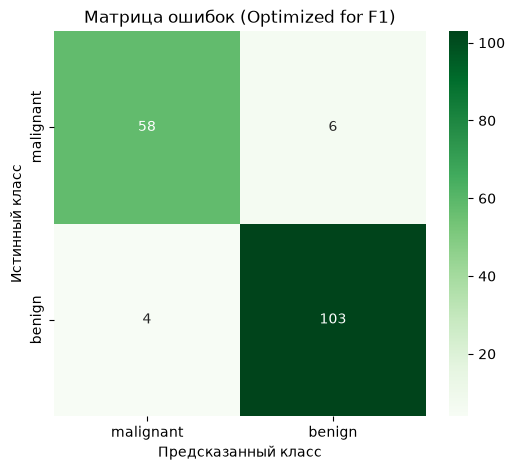

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
)
plt.title("Матрица ошибок (Optimized for F1)")
plt.ylabel("Истинный класс")
plt.xlabel("Предсказанный класс")
plt.show()


## Классификация с помощью  XGBoost

В библиотеке Scikit-Learn есть датасет картинок с рукописными цифрами, посмотрим на эти данные:

In [10]:
from sklearn.datasets import load_digits

digits = load_digits()
digits.images.shape

(1797, 8, 8)

Данные изображений представляют собой трехмерный массив: 1797 выборок,
каждая состоит из сетки пикселов размером 8 × 8. Визуализируем первую их сотню

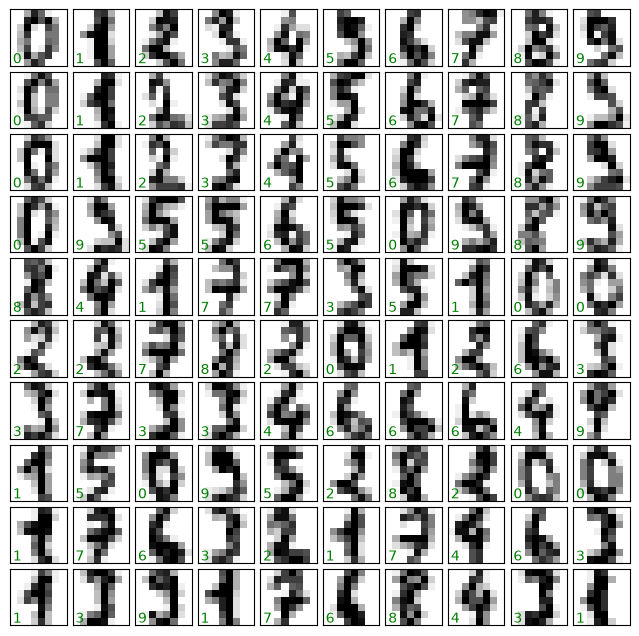

In [11]:
import matplotlib.pyplot as plt

# Подготавливаем к отображению
fig, axes = plt.subplots(
    10,
    10,
    figsize=(8, 8),
    subplot_kw={"xticks": [], "yticks": []},
    gridspec_kw=dict(hspace=0.1, wspace=0.1),
)
# и выводим 10 строк по 10 картинок цифр
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="binary", interpolation="nearest")
    # Зеленым цветом в углу подписывем картинки соответствующей цифрой
    ax.text(0.05, 0.05, str(digits.target[i]), transform=ax.transAxes, color="green")

Отложим для последующей проверки работы модели последние 10 цифр из датасета, признаки-предикторы поместим в X_last:

In [12]:
n = digits.images.shape[0]
m = n - 10
digit_s = digits.images[m:]
X_last = digits.data[m:, :]
# X_last.shape

а сами значения цифр - в y_last

In [13]:
y_last = digits.target[m:]
print("Цифры = ", y_last)

Цифры =  [5 4 8 8 4 9 0 8 9 8]


Отобразим эти картинки с цифрами

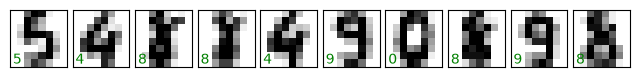

In [14]:
fig, axes = plt.subplots(
    1,
    10,
    figsize=(8, 8),
    subplot_kw={"xticks": [], "yticks": []},
    gridspec_kw=dict(hspace=0.1, wspace=0.1),
)
# и выводим строку из 10 картинок цифр
for i, ax in enumerate(axes.flat):
    ax.imshow(digit_s[i], cmap="binary", interpolation="nearest")
    # Зеленым цветом в углу подписывем картинки соответствующей цифрой
    ax.text(0.05, 0.05, str(y_last[i]), transform=ax.transAxes, color="green")

Для работы с этими данными в библиотеке Scikit-Learn нам нужно получить их
двумерное представление [n_samples, n_features]. Для этого мы будем трактовать каждый пиксел в изображении как признак, то есть «расплющим» массивы
пикселов так, чтобы каждую цифру представлял не квадратный массив  8х8 пикселов, а одномерный массив длиной 64 элемента. Кроме этого, нам понадобится целевой массив, задающий для каждой цифры предопределенную метку (правильный ответ). Эти два параметра встроены в набор данных цифр
в виде атрибутов data и target, соответственно:

In [15]:
X = digits.data[:m, :]
X.shape

(1787, 64)

In [16]:
y = digits.target[:m]
y.shape

(1787,)

Итого получаем 1787 выборок и 64 признака. Преобразуем
данные в двумерный вид, чтобы появилась возможность их визуализации:

In [17]:
from sklearn.manifold import Isomap

iso = Isomap(n_components=2)
iso.fit(digits.data[:m, :])
data_projected = iso.transform(digits.data[:m, :])
data_projected.shape

d:\projects\asu\venv\Lib\site-packages\sklearn\manifold\_isomap.py:362: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
d:\projects\asu\venv\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


(1787, 2)

Теперь наши данные стали двумерными. Построим график этих данных, чтобы
увидеть, можно ли что-то понять из их структуры

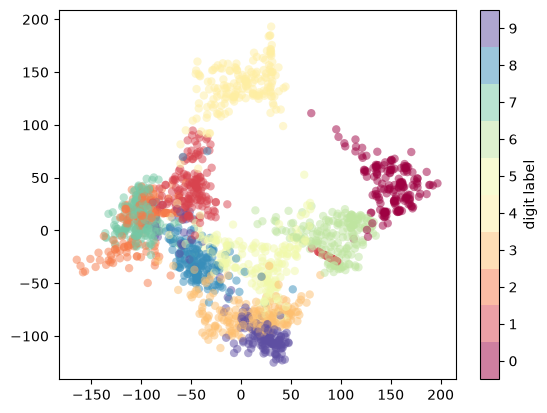

In [18]:
plt.scatter(
    data_projected[:, 0],
    data_projected[:, 1],
    c=digits.target[:m],
    edgecolor="none",
    alpha=0.5,
    cmap=plt.colormaps["Spectral"].resampled(10),
)
plt.colorbar(label="digit label", ticks=range(10))
plt.clim(-0.5, 9.5);

В целом различные группы достаточно хорошо разнесены в параметрическом
пространстве. Это значит, что даже довольно простой алгоритм классификации
с учителем (когда известны правильные ответы) должен работать на них достаточно хорошо.

Применим алгоритм классификации к нашим цифрам. Разобьем данные на обучающую и тестовую выборки, после чего обучим на первой из них модель XGBoost:

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

from xgboost import XGBClassifier

model = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.07)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Оценка качества предсказания модели с помощью кросстаблицы

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns

pd.crosstab(y_test, y_pred)

col_0,0,1,2,3,4,5,6,7,8,9
row_0,,,,,,,,,,
0,33,0,0,0,0,0,0,0,1,0
1,0,36,1,1,0,0,0,0,0,1
2,0,0,42,3,0,0,0,0,0,0
3,0,1,0,31,0,0,0,0,1,1
4,2,1,0,0,28,0,0,0,0,0
5,0,0,0,0,0,34,1,0,0,1
6,0,1,0,0,0,0,34,0,0,0
7,0,0,0,0,0,0,0,33,0,0
8,0,1,0,1,0,0,0,0,34,1


То же с цветом

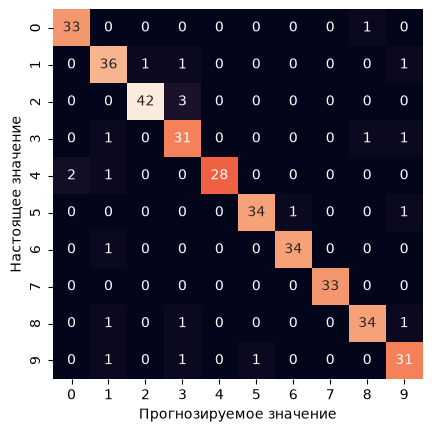

In [21]:
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(y_test, y_pred)
sns.heatmap(data=mat, square=True, annot=True, cbar=False, linecolor="white")
plt.xlabel("Прогнозируемое значение")
plt.ylabel("Настоящее значение");

Оценка качества предсказания модели с помощью метрик

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

print(model.score(X_test, y_test))

              precision    recall  f1-score   support

           0       0.94      0.97      0.96        34
           1       0.88      0.92      0.90        39
           2       0.98      0.93      0.95        45
           3       0.84      0.91      0.87        34
           4       1.00      0.90      0.95        31
           5       0.97      0.94      0.96        36
           6       0.97      0.97      0.97        35
           7       1.00      1.00      1.00        33
           8       0.94      0.92      0.93        37
           9       0.89      0.91      0.90        34

    accuracy                           0.94       358
   macro avg       0.94      0.94      0.94       358
weighted avg       0.94      0.94      0.94       358

0.9385474860335196


Спрогнозируем для последних 10 цифр (отоложенных вначале) их значения и сравним с реальностью

In [23]:
y_pred_last = model.predict(X_last)

print("Цифры фактические = ", *y_last, "\n Цифры по прогнозу =", *y_pred_last)

Цифры фактические =  5 4 8 8 4 9 0 8 9 8 
 Цифры по прогнозу = 5 4 8 1 4 9 0 8 9 8
